### Library importing



In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from prettytable import PrettyTable
from statistics import mean
from math import sqrt
from numpy import linalg as lin

# Sample two-dimensional functions

In [2]:
names = ['x^2 + 2xy + 3y^2',
         '4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3',
         '35x^2 + 71xy + 45y^2 - 8x + 62y + 11',
         '15x^2 + 3y^2 - 7x + 11y - 8']

functions = [lambda pars : pars[0]**2 + 2*pars[0]*pars[1] + 3*pars[1]**2,
             lambda pars : 4 * (pars[0] - 1)**2 + 3 * (pars[1] - 3)**2 + 4 * pars[0] * pars[1] - 3,
             lambda pars : 35 * pars[0] ** 2 + 71 * pars[0] * pars[1] + 45 * pars[1]**2 - 8 * pars[0] + 62 * pars[1] + 11,
             lambda pars : 15 * pars[0] ** 2 + 3 * pars[1] ** 2 - 7 * pars[0] + 11 * pars[1] - 8]

derivates = [lambda pars : np.array([2*pars[0] + 2*pars[1], 2*pars[0] + 6*pars[1]]),
             lambda pars : np.array([8*(pars[0] - 1) + 4*pars[1], 6*(pars[1] - 3) + 4 * pars[0]]),
             lambda pars : np.array([70 * pars[0] + 71 * pars[1] - 8, 90 * pars[1] + 71 * pars[0] + 62]),
             lambda pars : np.array([30 * pars[0] - 7, 6 * pars[1] + 11])]

near_points = [np.array([-1,1]), np.array([-1.0,4.0]), np.array([3.0,-4.0]), np.array([2.0,-3.0])]

far_points = [np.array([-5.0, 5.0]), np.array([-10.0,10.0]), np.array([7.0,-9.0]), np.array([-5.0,5.0])]

# Fibonacci's linear search Method

In [3]:
nums = np.array([0.0, 1.0])

def get_fibonacci_numbers(n):
  global nums
  if n < nums.size:
    return
  for i in range(nums.size - 1, n):
    nums = np.append(nums, nums[i] + nums[i - 1])

def fibonacci_number(n):
  global nums
  if (n < nums.size):
    return nums[n]
  get_fibonacci_numbers(n)
  return nums[n]

#func = lambda x : f(xk - x * Direction) 
def fibonacci_method(func, left_border, right_border, epsilon=0.0001):
  left = left_border
  right = right_border
  n = 0
  lim = (right_border - left_border) / epsilon
  while(fibonacci_number(n) <= lim):
    n += 1
  a = left_border
  b = right_border
  d = right_border - left_border
  for i in range(1, n + 1):
    d = d * (fibonacci_number(n - i)/fibonacci_number(n - i + 1))
    x1 = b - d
    x2 = a + d
    if func(x1) <= func(x2):
      b = x2
    else:
      a = x1
  return (a + b) / 2


## Best step finding

In [4]:
def linear_search(condition, step=0.01):
  lim_right = step
  while lim_right < 100 and condition(lim_right):
    lim_right += step
  return lim_right

def backtracking(condition):
  alpha = 10000000
  tau = 0.5
  while condition(alpha) == False:
    alpha *= tau
  return alpha

def find_step(function, derivate, xk, wolfe=False, epsilon=0.001):
  difArray = derivate(xk)
  if (lin.norm(difArray) != 0):
    direction = -1 * difArray / lin.norm(difArray)
  else:
    direction = -1 * difArray[::]
  f = lambda alpha : function(xk + alpha * direction)
  if (wolfe):
    c1 = 0.001
    condition = lambda alpha : f(alpha) <= function(xk) + c1 * alpha * (difArray @ np.transpose(direction))
    return backtracking(condition)
  else:
    condition =  lambda alpha : f(0) > f(alpha)
    right_border = linear_search(condition)
  return fibonacci_method(f, 0, right_border, epsilon)


# Gradient descent implementation



In [5]:
#Starting from 0
def gradient_descent(function, derivate, n = 2, wolf=False, initial_points=None, epsilon=0.000001, step = None):
  iteration = 0
  if (initial_points is not None):
    last_points = ini_points = initial_points[::]
  else:
    last_points = initial_points = np.zeros(n)
  points = last_points[::]
  ans = np.array(points[::])
  dif = np.zeros(points.size);
  while iteration <= 10000:
    difArray = derivate(points[::])
    if (lin.norm(difArray) != 0):
      direction = -1 * difArray / lin.norm(difArray)
    else:
      direction = -1 * difArray[::]
    if (wolf == False):
      learning_rate = step if step else find_step(function, derivate, points, False, epsilon)
    else:
      learning_rate = find_step(function, derivate, points, True, epsilon)
    dif = learning_rate * direction
    points = last_points[::] + dif
    ans = np.append(ans, points[::])
    if (lin.norm(difArray) < epsilon) or (lin.norm(points - last_points) < epsilon) or (abs(function(points) - function(last_points)) < epsilon):
      break
    iteration += 1
    last_points = points[::]
  return ans, iteration, last_points
#gradient_descent(functions[0], derivates[0], 2, False, np.array([5.0, 5.0])) 

## Function for displaying results

In [6]:
def plot_graph(function,derivate, learning_rate=None, initial_points=np.array([-10,10]), sizex=10, sizey=10, wolfe=False):
    x = np.linspace(-sizex, sizex, 100)
    y = np.linspace(-sizey, sizey, 100)
    X, Y = np.meshgrid(x, y)
    F = function(np.array([X, Y]))
    points, iter, last_points = gradient_descent(function, derivate, 2, wolfe, initial_points, 0.000001, learning_rate)
    print("Found point: ", last_points)
    if (iter > 10000):
      print("did not converge")
    else:
      print("in", iter, "iterations")
    fig, ax = plt.subplots(figsize=(8, 6))
    contour = ax.contour(X, Y, F, levels=20, cmap='coolwarm')
    x_0 = np.array(points[0:len(points):2])
    y_0 = np.array(points[1:len(points):2])
    ax.plot(x_0, y_0, linestyle = '--', color='green')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.clabel(contour, inline=True, fontsize=8)
    plt.show()


## Convergence of sample functions with Wolfe's condition

Computing for x^2 + 2xy + 3y^2:
Found point:  [-0.00094865  0.00010561]
in 16 iterations


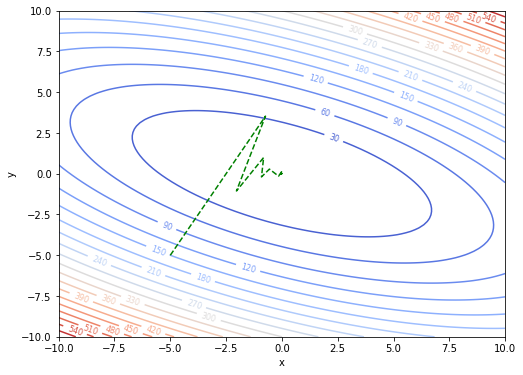

Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-0.75047236  3.49990835]
in 14 iterations


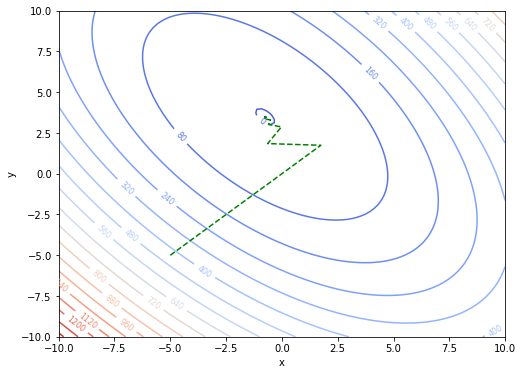

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.0671397  -3.89767355]
in 50 iterations


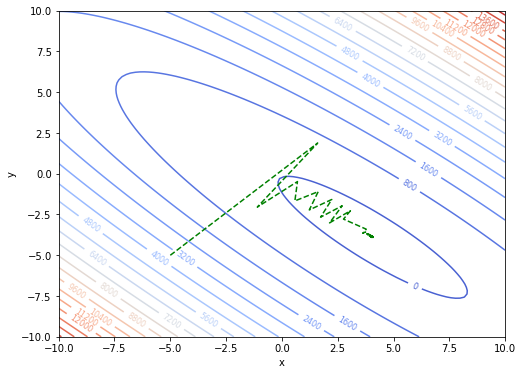

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23343905 -1.83309421]
in 19 iterations


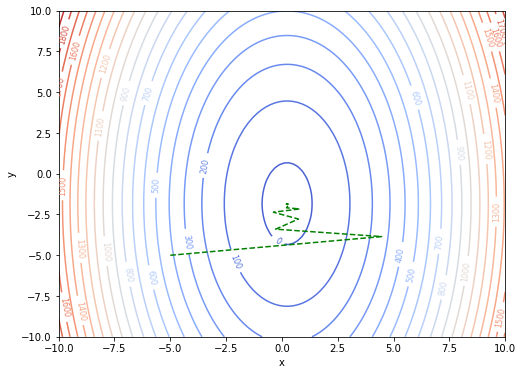

In [ ]:
for name, function,derivate in zip(names, functions,derivates):
  print(f"Computing for {name}:")
  plot_graph(function,derivate, 0.001, np.array([-5, -5]), 10, 10, True)

## Gradient descent testing for constant step small size



Computring for x^2 + 2xy + 3y^2:
Found point:  [-5.09638886  2.1500204 ]
did not converge


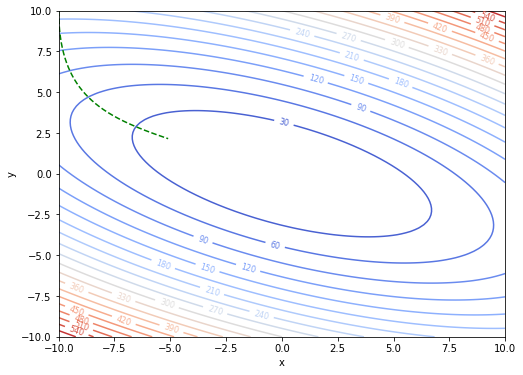

Computring for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-1.84785655  4.90112926]
did not converge


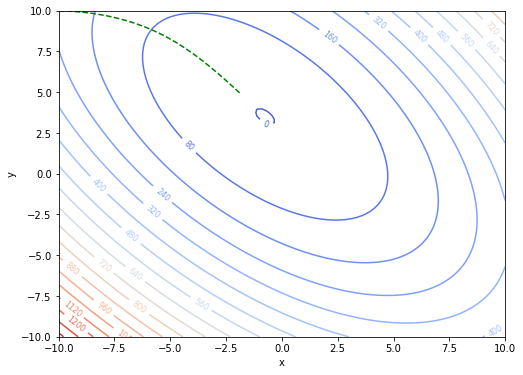

Computring for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [-3.53041179  2.70515229]
did not converge


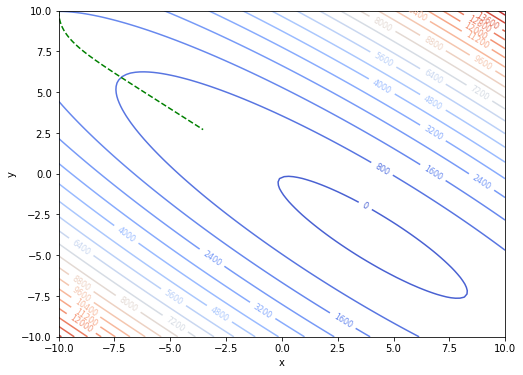

Computring for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [-1.02629311  5.95010062]
did not converge


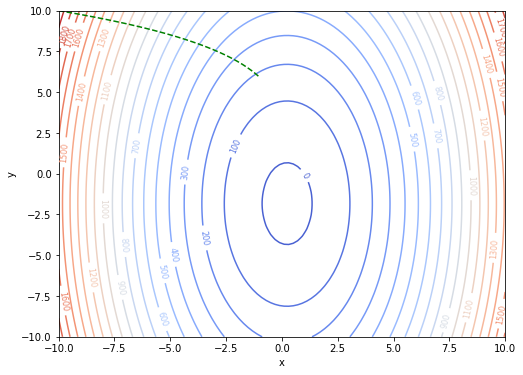

In [ ]:
for name, function,derivate in zip(names, functions,derivates):
  print(f"Computing for {name}:")
  plot_graph(function,derivate,0.001)

## Gradient descent with constant big step

Computing for x^2 + 2xy + 3y^2:
Found point:  [0.64928069 1.56750224]
did not converge


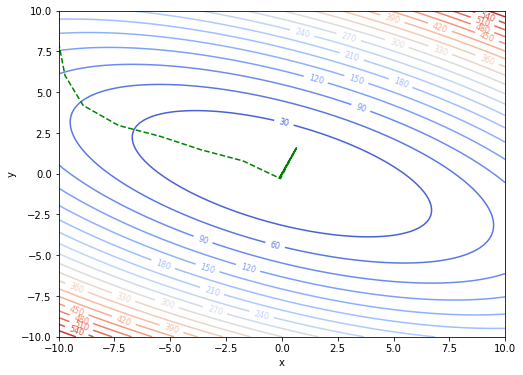

Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-1.75450614  2.71570531]
did not converge


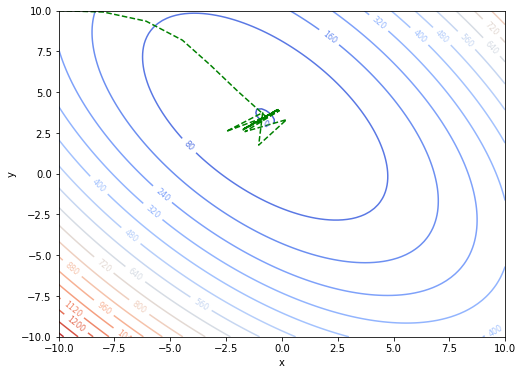

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 3.41211404 -4.65342447]
did not converge


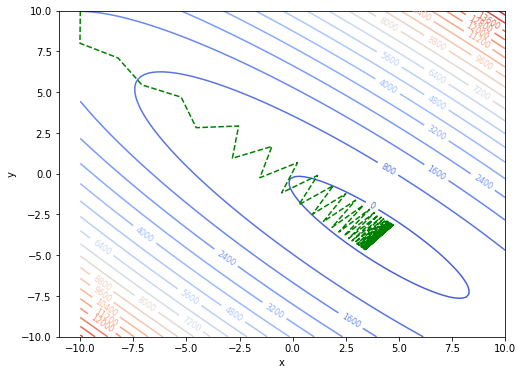

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [-0.69444596 -1.83333333]
did not converge


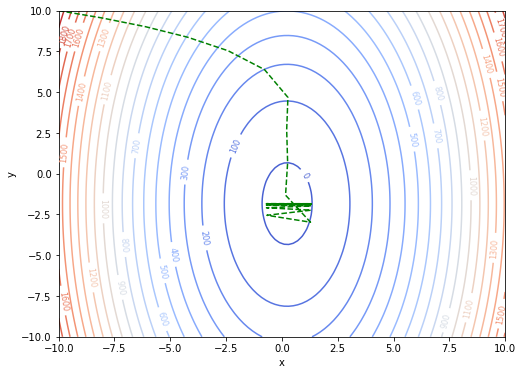

In [ ]:
for name, function,derivate in zip(names, functions,derivates):
  print(f"Computing for {name}:")
  plot_graph(function,derivate,2)

## Gradient Descent with starting near point

Computing for x^2 + 2xy + 3y^2:
Found point:  [-0.00037439  0.00015508]
in 1553 iterations


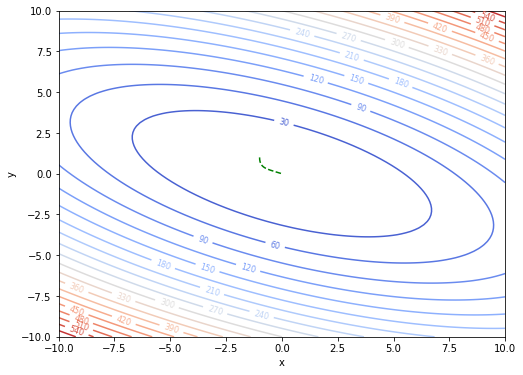

Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-0.74931911  3.49941285]
in 578 iterations


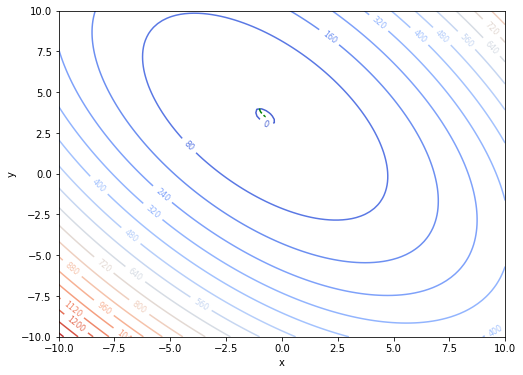

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.06771105 -3.89901914]
did not converge


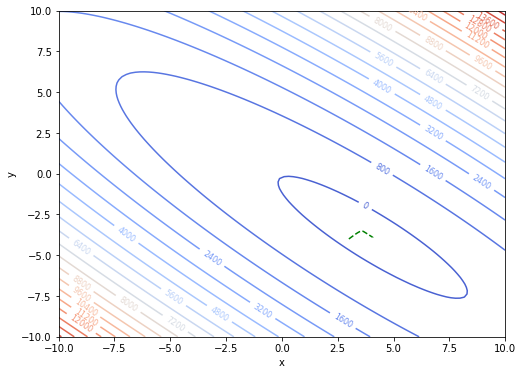

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23376483 -1.83333333]
did not converge


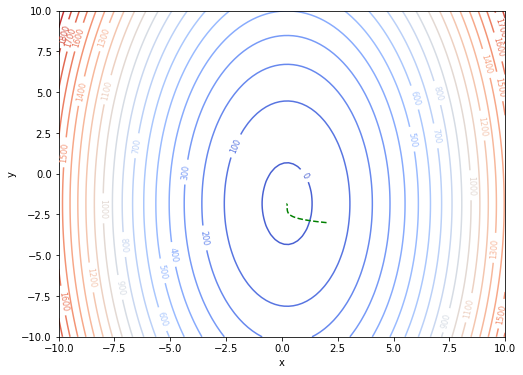

In [ ]:
for name, function,derivate,near_point  in zip(names, functions,derivates,near_points):
  print(f"Computing for {name}:")
  plot_graph(function,derivate, 0.001, near_point)

## Gradient Descent with starting far point

Computing for x^2 + 2xy + 3y^2:
Found point:  [-0.00035219  0.00014588]
in 7766 iterations


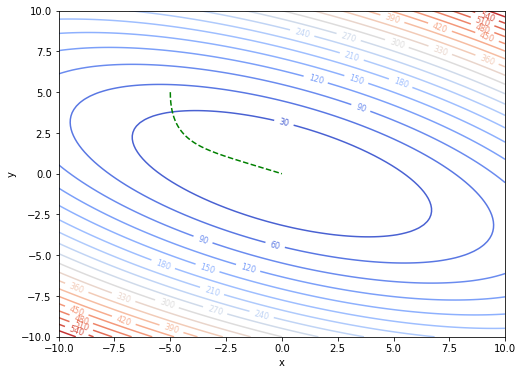

Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-1.84785655  4.90112926]
did not converge


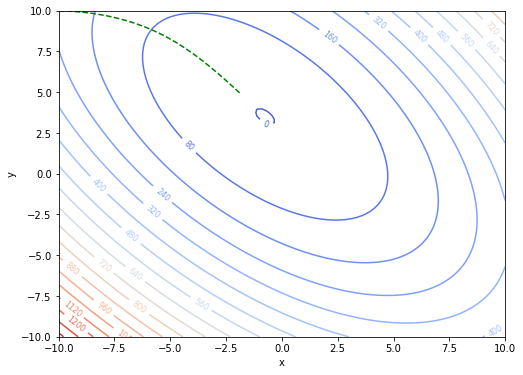

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.06823966 -3.89841086]
did not converge


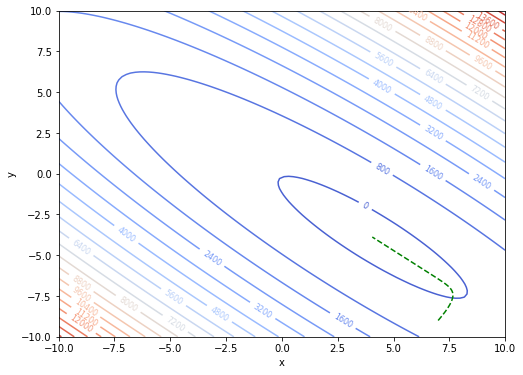

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23333333 -1.83300535]
did not converge


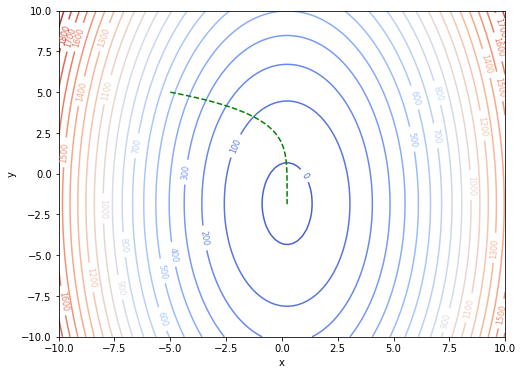

In [ ]:
for name, function,derivate,far_point  in zip(names, functions,derivates,far_points):
  print(f"Computing for {name}:")
  plot_graph(function,derivate, 0.001, far_point)

## Gradient Descent with steepest descent optimization

Computing for x^2 + 2xy + 3y^2:
Found point:  [-0.00050232  0.00050417]
in 18 iterations


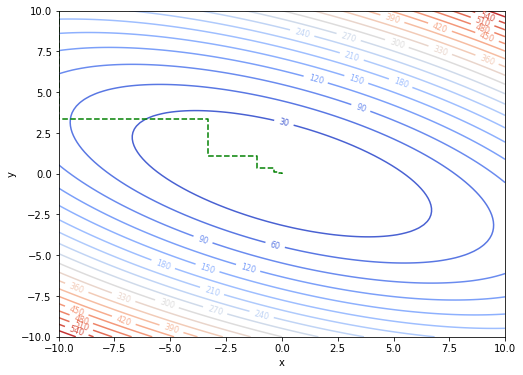

Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-0.75057665  3.50040552]
in 18 iterations


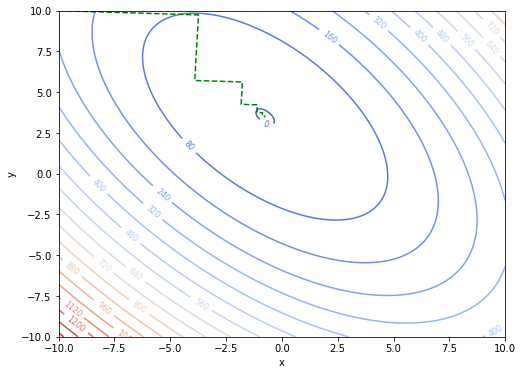

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.06757213 -3.89760379]
in 88 iterations


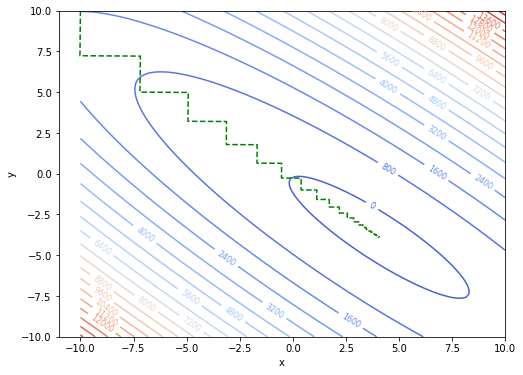

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23335088 -1.83293655]
in 11 iterations


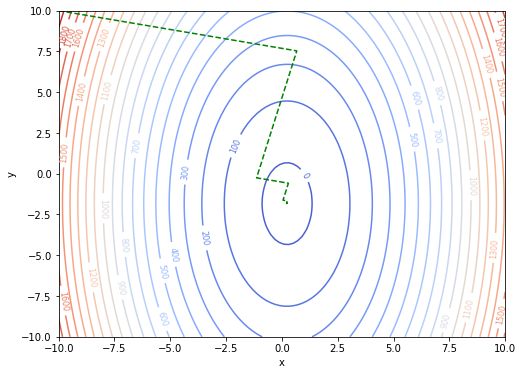

In [ ]:
for name, function,derivate in zip(names, functions,derivates):
  print(f"Computing for {name}:")
  plot_graph(function,derivate)

## Gradient Descent with starting near point and the steepest descent optimization

Computing for x^2 + 2xy + 3y^2:
Found point:  [-0.00136981  0.00045706]
in 13 iterations


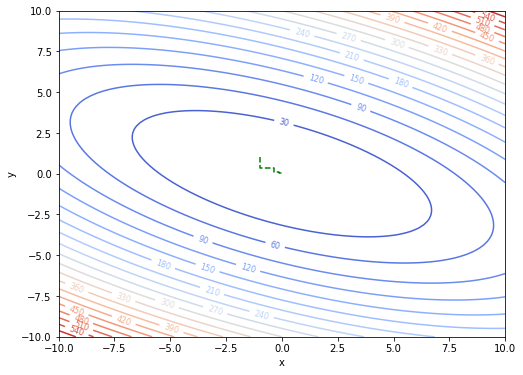

Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-0.75034331  3.50068552]
in 12 iterations


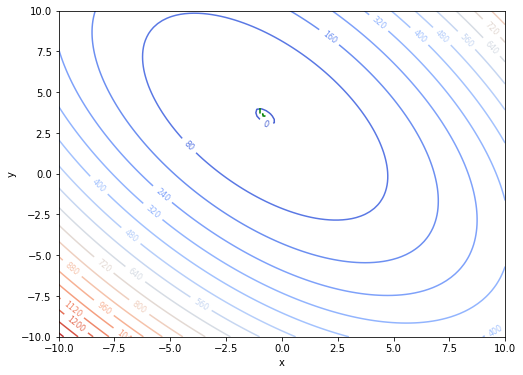

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.06824598 -3.89834263]
in 6 iterations


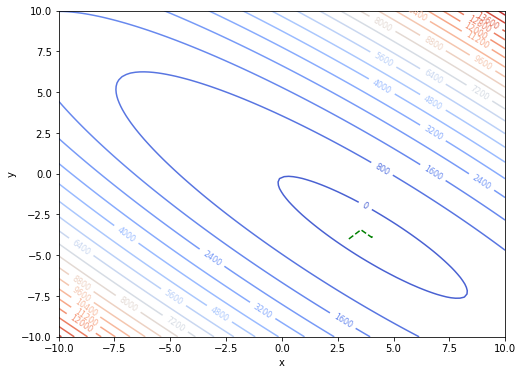

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23356712 -1.83348685]
in 6 iterations


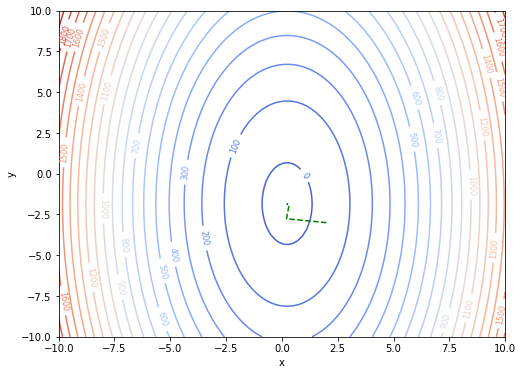

In [ ]:
for name, function,derivate,near_point  in zip(names, functions,derivates,near_points):
  print(f"Computing for {name}:")
  plot_graph(function,derivate,None, near_point)

## Gradient Descent with starting far point and the steepest descent optimization

Computing for x^2 + 2xy + 3y^2:
Found point:  [-0.0007571   0.00075878]
in 16 iterations


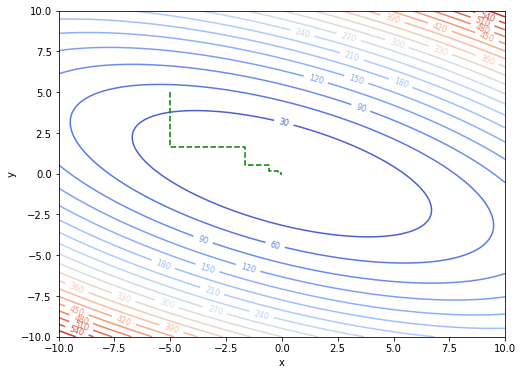

Computing for 4(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [-0.75057665  3.50040552]
in 18 iterations


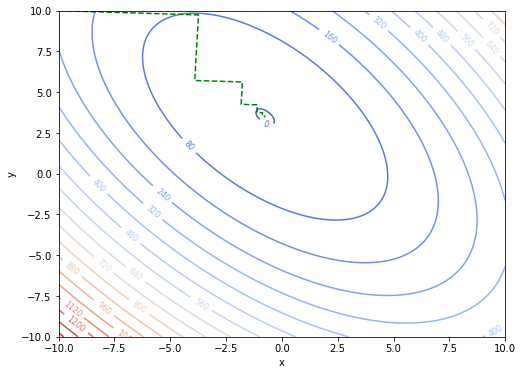

Computing for 35x^2 + 71xy + 45y^2 - 8x + 62y + 11:
Found point:  [ 4.06838291 -3.89847815]
in 16 iterations


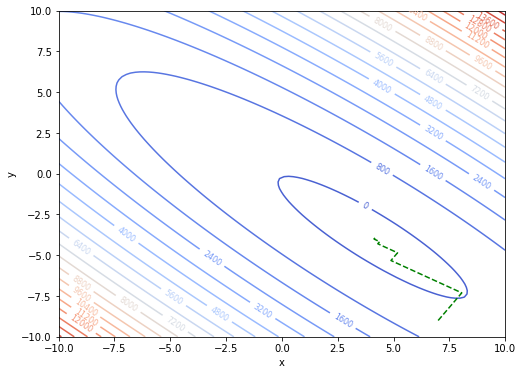

Computing for 15x^2 + 3y^2 - 7x + 11y - 8:
Found point:  [ 0.23336292 -1.83275974]
in 11 iterations


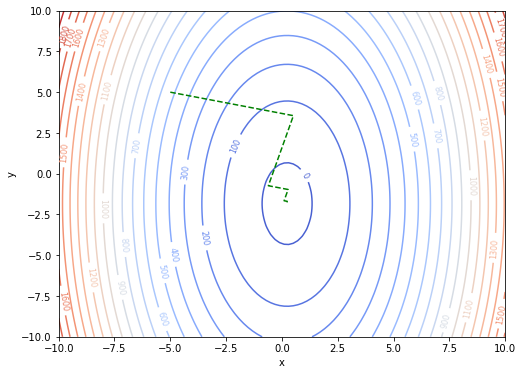

In [ ]:
for name, function,derivate,far_point  in zip(names, functions,derivates,far_points):
  print(f"Computing for {name}:")
  plot_graph(function,derivate, None, far_point)

# Gradient descent (steepest descent) against poorly conditioned functions (scaling)

In [ ]:
names_with_scaling = ['1000000x^2 + 2xy + 3y^2',
         '1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3',
         '35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11',
         '15x^2 + 1000000y^2 - 7x + y - 8']

functions_with_scaling = [lambda pars : 1000000*pars[0]**2 + 2*pars[0]*pars[1] + 3*pars[1]**2,
             lambda pars : 1000000 * (pars[0] - 1)**2 + 3 * (pars[1] - 3)**2 + 4 * pars[0] * pars[1] - 3,
             lambda pars : 35 * pars[0] ** 2 + 71 * pars[0] * pars[1] + 1000000 * pars[1]**2 - 8 * pars[0] + 62 * pars[1] + 11,
             lambda pars : 15 * pars[0] ** 2 + 1000000 * pars[1] ** 2 - 7 * pars[0] + pars[1] - 8]

derivates_with_scaling = [lambda pars : np.array([2000000*pars[0] + 2*pars[1], 2*pars[0] + 6*pars[1]]),
             lambda pars : np.array([2000000*(pars[0] - 1) + 4*pars[1], 6*(pars[1] - 3) + 4 * pars[0]]),
             lambda pars : np.array([70 * pars[0] + 71 * pars[1] - 8, 2000000 * pars[1] + 71 * pars[0] + 62]),
             lambda pars : np.array([30 * pars[0] - 7, 2000000 * pars[1] + 1])]

## Near Starting point

Computing for 1000000x^2 + 2xy + 3y^2:
Found point:  [-1.10231670e-06  3.09749671e-01]
did not converge


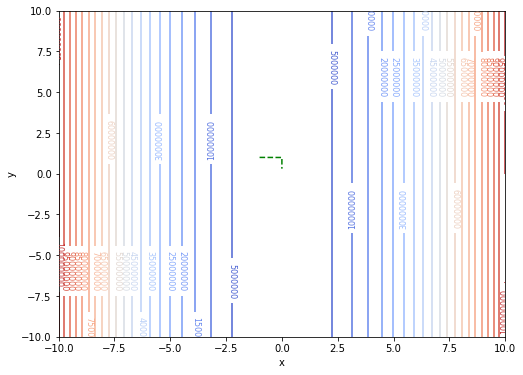

Computing for 1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [0.999996   2.42178226]
in 187 iterations


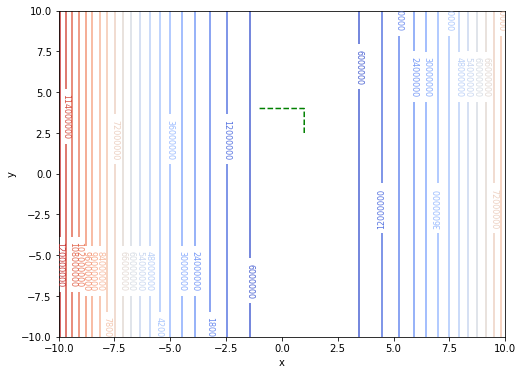

Computing for 35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11:
Found point:  [ 1.15748745e-01 -3.44606792e-05]
in 160 iterations


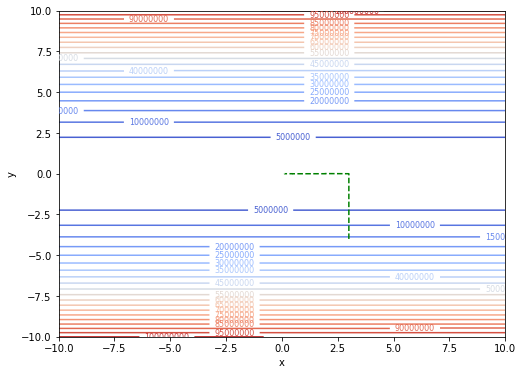

Computing for 15x^2 + 1000000y^2 - 7x + y - 8:
Found point:  [2.60228888e-01 2.60363511e-07]
in 2002 iterations


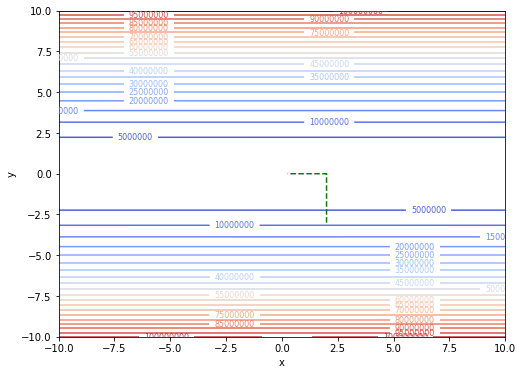

In [ ]:
for name_with_scaling, function_with_scaling,derivate_with_scaling,near_point in zip(names_with_scaling, functions_with_scaling,derivates_with_scaling,near_points):
  print(f"Computing for {name_with_scaling}:")
  plot_graph(function_with_scaling,derivate_with_scaling, None,near_point, 10, 10)

## Far Starting point

Computing for 1000000x^2 + 2xy + 3y^2:
Found point:  [9.03255747e-07 9.97808858e-02]
in 69 iterations


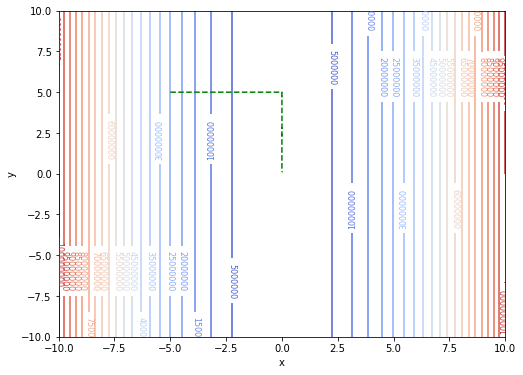

Computing for 1000000(x - 1)^2 + 3(y - 3)^2 + 4xy - 3:
Found point:  [0.99999457 2.49097769]
in 87 iterations


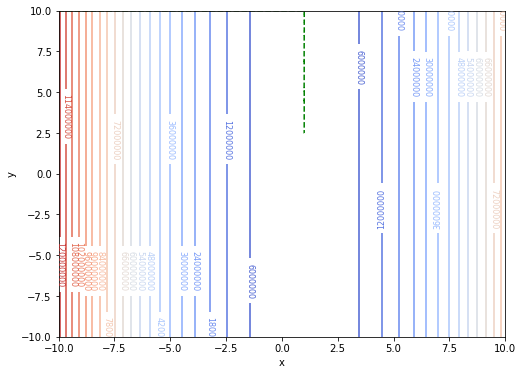

Computing for 35x^2 + 71xy + 1000000y^2 - 8x + 62y + 11:
Found point:  [ 1.18261535e-01 -3.46570443e-05]
in 398 iterations


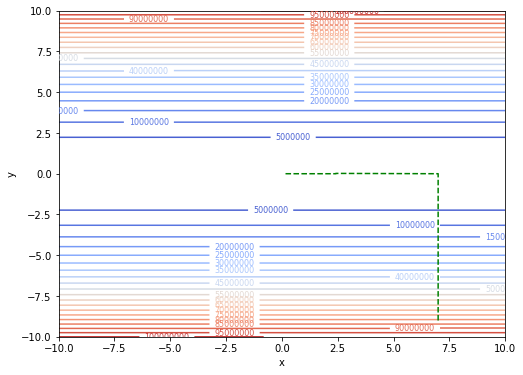

Computing for 15x^2 + 1000000y^2 - 7x + y - 8:
Found point:  [2.00903675e-01 5.03126355e-07]
in 4921 iterations


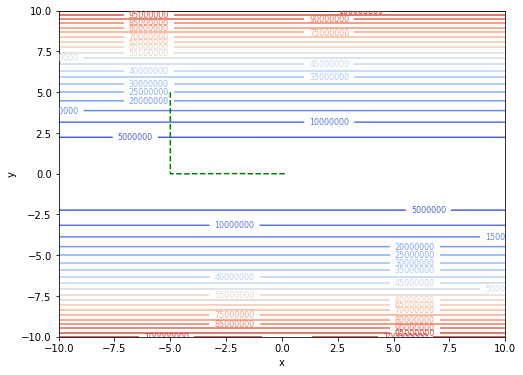

In [ ]:
for name_with_scaling, function_with_scaling,derivate_with_scaling,far_point in zip(names_with_scaling, functions_with_scaling,derivates_with_scaling,far_points):
  print(f"Computing for {name_with_scaling}:")
  plot_graph(function_with_scaling,derivate_with_scaling, None,far_point, 10, 10)

# Effectiveness acording to Rosenbrock's function

Testing for: Rosenbrock function to test effectiveness: 100(y - x^2)^2 + (1 - x)^2
Found point:  [1.00714223 1.01436127]
in 107 iterations


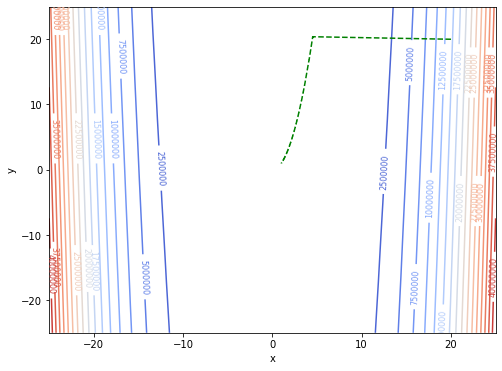

In [ ]:
#Rosenbrok Function

name = 'Rosenbrock function to test effectiveness: 100(y - x^2)^2 + (1 - x)^2'
function =  lambda pars : 100 * (pars[1] - pars[0] ** 2) ** 2 + (1 - pars[0]) ** 2
derivate = lambda pars : np.array([400 * pars[0]**3 + (2 - 400 * pars[1]) * pars[0] - 2,
                                     200 * (pars[1] - pars[0]**2)])

# function, derivate, n = 2, wolf=False, initial_points=None, epsilon=0.000001, step = None
print("Testing for:", name)
plot_graph(function, derivate, None, np.array([20,20]), 25, 25)

## And now with Wolfe's Condition

Testing for: Rosenbrock function to test effectiveness: 100(y - x^2)^2 + (1 - x)^2
Found point:  [2.69362738 7.25810395]
in 4401 iterations


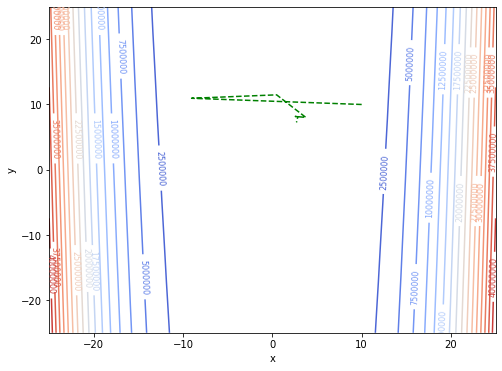

Found point:  [1.02623551 1.05293378]
in 6514 iterations


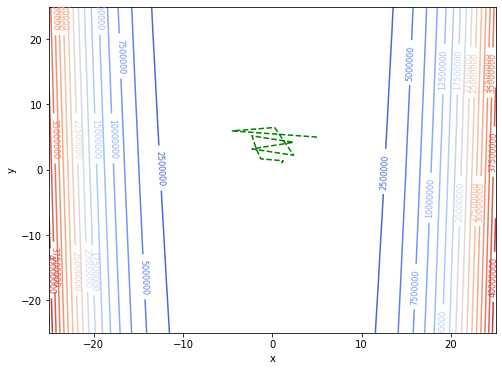

In [ ]:
#Rosenbrok Function

name = 'Rosenbrock function to test effectiveness: 100(y - x^2)^2 + (1 - x)^2'
function =  lambda pars : 100 * (pars[1] - pars[0] ** 2) ** 2 + (1 - pars[0]) ** 2
derivate = lambda pars : np.array([400 * pars[0]**3 + (2 - 400 * pars[1]) * pars[0] - 2,
                                     200 * (pars[1] - pars[0]**2)])

# function, derivate, n = 2, wolf=False, initial_points=None, epsilon=0.000001, step = None
print("Testing for:", name)
plot_graph(function, derivate, None, np.array([10, 10]), 25, 25, True)
plot_graph(function, derivate, None, np.array([5, 5]), 25, 25, True)

# Generator of cuadratic functions

In [ ]:
#Function generating a quadratic function with n variables an condition number k

# Based on
# f(x) = 1/2(x^T)Qx - (b^T)x
# returns a function and its derivate
def generate(n, k):
  diag = np.random.randint(1, k + 1, n)
  diag[0] = 1
  diag[-1] = k
  np.random.shuffle(diag)
  diag = np.diag(diag)
  b = np.random.randint(n, size=(n))
  return lambda x : (1.0 / 2.0) * (x @ diag @ np.transpose(x) - b @ np.transpose(x)), lambda x : np.transpose(x) @ diag - b

# f, d = generate(3, 6)
# print(f(np.array([1.0, 1.0, 1.0])))
# print(d(np.array([1.0, 1.0, 1.0])))

## Gradient descent against different number of variables and condition 

In [ ]:
def test_condition(wolfe=False, ns=(2, 3, 5, 10, 50, 100), ks=(1, 2, 5, 10, 100, 500)):
  t = PrettyTable(['Condition number', 'number of variables', 'Average iterations needed', 'converged', 'diverged'])
  for k in ks:
    average_for_k = 0.0
    seen_dimensions = 0;
    for n in ns:
      sum = 0
      converged = 0
      num_of_exp = 10
      for i in range(num_of_exp):
        function, derivate = generate(n, k)
        iter = gradient_descent(function, derivate, n, wolfe)[1]
        if (iter <= 10000):
          converged += 1
          sum += iter
      if (converged == 0):
        break
      sum /= converged
      t.add_row([k, n, sum, converged, num_of_exp - converged])
  print(t)

In [ ]:
test_condition()

+------------------+---------------------+---------------------------+-----------+----------+
| Condition number | number of variables | Average iterations needed | converged | diverged |
+------------------+---------------------+---------------------------+-----------+----------+
|        1         |          2          |            0.7            |     10    |    0     |
|        1         |          3          |            1.0            |     10    |    0     |
|        1         |          5          |            1.0            |     10    |    0     |
|        1         |          10         |            1.0            |     10    |    0     |
|        1         |          50         |            1.5            |     10    |    0     |
|        1         |         100         |            3.3            |     10    |    0     |
|        2         |          2          |            1.0            |     10    |    0     |
|        2         |          3          |            2.2   

## And now with Wolfe's condition

In [ ]:
test_condition(True, (2, 3, 5, 10, 50, 100, 500, 750, 1000), (1, 2, 5, 10, 100, 500, 750, 1000))

+------------------+---------------------+---------------------------+-----------+----------+
| Condition number | number of variables | Average iterations needed | converged | diverged |
+------------------+---------------------+---------------------------+-----------+----------+
|        1         |          2          |            0.8            |     10    |    0     |
|        1         |          3          |            1.0            |     10    |    0     |
|        1         |          5          |            1.0            |     10    |    0     |
|        1         |          10         |            1.0            |     10    |    0     |
|        1         |          50         |            1.0            |     10    |    0     |
|        1         |         100         |            1.0            |     10    |    0     |
|        1         |         500         |            1.0            |     10    |    0     |
|        1         |         750         |            1.0   